<a href="https://colab.research.google.com/github/Nhut214/vietnamese_student_feedback_sentiment_analysis/blob/main/notebooks/03_LSTM_UIT_VSFC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Đường dẫn dữ liệu: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/Data
Train: (11426, 3)
Validation: (1583, 3)
Test: (3166, 3)

Phân bố nhãn tập train:
sentiment
Negative    5325
Neutral      458
Positive    5643
Name: count, dtype: int64


,sentence,sentiment,topic
0,slide giáo trình đầy đủ .,2,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0
2,đi học đầy đủ full điểm chuyên cần .,0,1
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,0
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,0


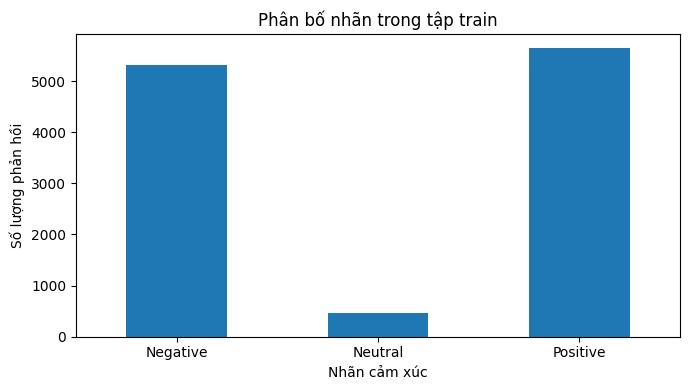

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

LABEL_IDS = [0, 1, 2]
LABEL_NAMES = ["Negative", "Neutral", "Positive"]
ID2LABEL = {0: "Negative", 1: "Neutral", 2: "Positive"}
LABEL2ID = {"Negative": 0, "Neutral": 1, "Positive": 2}

DATA_DIR = r"/content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/Data"

TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
VALIDATION_PATH = os.path.join(DATA_DIR, "validation.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

for path in [TRAIN_PATH, VALIDATION_PATH, TEST_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Không tìm thấy file: {path}\n"
            "Hãy kiểm tra lại tên thư mục và tên file trong Google Drive."
        )

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)

def clean_dataframe(df, name):
    required_columns = {"sentence", "sentiment"}
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Tập {name} thiếu các cột bắt buộc: {missing_columns}"
        )

    cleaned = df.dropna(subset=["sentence", "sentiment"]).copy()
    cleaned["sentence"] = cleaned["sentence"].astype(str).str.strip()
    cleaned["sentiment"] = pd.to_numeric(
        cleaned["sentiment"],
        errors="coerce"
    )
    cleaned = cleaned.dropna(subset=["sentiment"])
    cleaned["sentiment"] = cleaned["sentiment"].astype(int)
    cleaned = cleaned[
        cleaned["sentiment"].isin(LABEL_IDS)
    ]
    cleaned = cleaned[
        cleaned["sentence"].str.len() > 0
    ].reset_index(drop=True)

    return cleaned

train_df = clean_dataframe(train_df, "train")
val_df = clean_dataframe(val_df, "validation")
test_df = clean_dataframe(test_df, "test")

# Các biến nhãn được tạo ngay sau khi đọc dữ liệu.
y_train = train_df["sentiment"].to_numpy(dtype=np.int64)
y_val = val_df["sentiment"].to_numpy(dtype=np.int64)
y_test = test_df["sentiment"].to_numpy(dtype=np.int64)

print("Đường dẫn dữ liệu:", DATA_DIR)
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nPhân bố nhãn tập train:")
print(
    train_df["sentiment"]
    .value_counts()
    .reindex(LABEL_IDS, fill_value=0)
    .rename(index=ID2LABEL)
)

display(train_df.head())

train_counts = (
    train_df["sentiment"]
    .value_counts()
    .reindex(LABEL_IDS, fill_value=0)
    .rename(index=ID2LABEL)
)

train_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Phân bố nhãn trong tập train")
plt.xlabel("Nhãn cảm xúc")
plt.ylabel("Số lượng phản hồi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

RESULTS = []

def evaluate_predictions(
    model_name,
    experiment,
    y_true,
    y_pred,
    show_confusion_matrix=True
):
    accuracy = accuracy_score(y_true, y_pred)

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average="macro",
            zero_division=0
        )
    )

    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=LABEL_IDS,
        average="weighted",
        zero_division=0
    )

    class_precision, class_recall, class_f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average=None,
            zero_division=0
        )
    )

    result = {
        "Model": model_name,
        "Experiment": experiment,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Negative Precision": class_precision[0],
        "Negative Recall": class_recall[0],
        "Negative F1": class_f1[0],
        "Neutral Precision": class_precision[1],
        "Neutral Recall": class_recall[1],
        "Neutral F1": class_f1[1],
        "Positive Precision": class_precision[2],
        "Positive Recall": class_recall[2],
        "Positive F1": class_f1[2],
        "Neutral Support": int(support[1]),
    }

    RESULTS.append(result)

    print(f"\n{model_name} — {experiment}")
    print("=" * 72)
    print(
        classification_report(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            target_names=LABEL_NAMES,
            digits=4,
            zero_division=0
        )
    )

    if show_confusion_matrix:
        matrix = confusion_matrix(
            y_true,
            y_pred,
            labels=LABEL_IDS
        )
        display_matrix = ConfusionMatrixDisplay(
            matrix,
            display_labels=LABEL_NAMES
        )
        display_matrix.plot(values_format="d")
        plt.title(f"{model_name} — {experiment}")
        plt.tight_layout()
        plt.show()

    return result


def export_results(filename):
    if not RESULTS:
        raise ValueError("Chưa có kết quả để xuất.")

    result_df = (
        pd.DataFrame(RESULTS)
        .drop_duplicates(
            subset=["Model", "Experiment"],
            keep="last"
        )
        .reset_index(drop=True)
    )

    metric_columns = [
        column
        for column in result_df.columns
        if column not in [
            "Model",
            "Experiment",
            "Neutral Support"
        ]
    ]

    display_df = result_df.copy()
    display_df[metric_columns] = (
        display_df[metric_columns].round(4)
    )

    display(display_df)

    output_path = os.path.join(
        "/content/drive/MyDrive/NC_MatCanBang_UIT_VSFC",
        filename
    )
    result_df.to_csv(output_path, index=False)

    print("Đã lưu kết quả tại:", output_path)
    return result_df


In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print(
    "GPU khả dụng:",
    tf.config.list_physical_devices("GPU")
)

MAX_TOKENS = 30000
SEQUENCE_LENGTH = 80
EMBEDDING_DIM = 128
RNN_UNITS = 128
BATCH_SIZE = 64
EPOCHS = 8

text_vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize=None
)

text_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        train_df["sentence"].astype(str).values
    ).batch(256)
)

VOCAB_SIZE = len(
    text_vectorizer.get_vocabulary()
)

class_values = np.array(LABEL_IDS)
class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=class_values,
    y=y_train
)

CLASS_WEIGHT = {
    int(label): float(weight)
    for label, weight in zip(
        class_values,
        class_weight_values
    )
}

print("Kích thước từ vựng:", VOCAB_SIZE)
print("Trọng số lớp:", CLASS_WEIGHT)

def create_tf_dataset(df, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (
            df["sentence"].astype(str).values,
            df["sentiment"].to_numpy(
                dtype=np.int32
            )
        )
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return (
        dataset
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

train_dataset = create_tf_dataset(
    train_df,
    shuffle=True
)
validation_dataset = create_tf_dataset(val_df)
test_dataset = create_tf_dataset(test_df)

print("Số mẫu train:", len(y_train))
print("Số mẫu validation:", len(y_val))
print("Số mẫu test:", len(y_test))


TensorFlow: 2.20.0
GPU khả dụng: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Kích thước từ vựng: 2516
Trọng số lớp: {0: 0.7152425665101722, 1: 8.315866084425036, 2: 0.674936499497903}
Số mẫu train: 11426
Số mẫu validation: 1583
Số mẫu test: 3166



## 1. Xây dựng mô hình LSTM

Kiến trúc:

`Text → TextVectorization → Embedding → LSTM → Dense → Softmax`


In [ ]:

def build_lstm_model():
    text_input = keras.Input(
        shape=(),
        dtype=tf.string,
        name="sentence"
    )

    x = text_vectorizer(text_input)

    x = layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name="embedding"
    )(x)

    x = layers.LSTM(
        RNN_UNITS,
        name="lstm"
    )(x)

    x = layers.Dropout(0.4)(x)
    x = layers.Dense(
        64,
        activation="relu"
    )(x)
    x = layers.Dropout(0.3)(x)

    output = layers.Dense(
        3,
        activation="softmax",
        name="sentiment"
    )(x)

    model = keras.Model(
        inputs=text_input,
        outputs=output
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


In [ ]:

def train_and_evaluate_rnn(
    model,
    model_name,
    experiment,
    class_weight=None
):
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=1,
            min_lr=1e-5
        )
    ]

    history = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=EPOCHS,
        class_weight=class_weight,
        callbacks=callbacks,
        verbose=1
    )

    probabilities = model.predict(
        test_dataset,
        verbose=0
    )
    predictions = probabilities.argmax(axis=1)

    evaluate_predictions(
        model_name,
        experiment,
        y_test,
        predictions
    )

    history_df = pd.DataFrame(history.history)

    history_df[["loss", "val_loss"]].plot(
        figsize=(7, 4)
    )
    plt.title(
        f"Loss — {model_name} — {experiment}"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.tight_layout()
    plt.show()

    return model, history



## 2. LSTM trên dữ liệu gốc


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sentence            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 80)        │          0 │ sentence[0][0]    │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 80, 128)   │    322,048 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 80)        │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 128)       │    131,584 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sentiment (Dense)   │ (None, 3)         │        195 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 462,083 (1.76 MB)

 Trainable params: 462,083 (1.76 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.8220 - loss: 0.4721 - val_accuracy: 0.8958 - val_loss: 0.3132 - learning_rate: 0.0010
Epoch 2/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9078 - loss: 0.2835 - val_accuracy: 0.9040 - val_loss: 0.2916 - learning_rate: 0.0010
Epoch 3/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9241 - loss: 0.2346 - val_accuracy: 0.9033 - val_loss: 0.2892 - learning_rate: 0.0010
Epoch 4/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9361 - loss: 0.2071 - val_accuracy: 0.9097 - val_loss: 0.2859 - learning_rate: 0.0010
Epoch 5/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9409 - loss: 0.1870 - val_accuracy: 0.9185 - val_loss: 0.2793 - learning_rate: 0.0010
Epoch 6/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9480 - loss: 0.1689 - val_accuracy: 0.9185 - val_loss: 0.2997 - learning_rate: 0.0010
Epoch 7/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9569 - loss: 0.1400 - val_

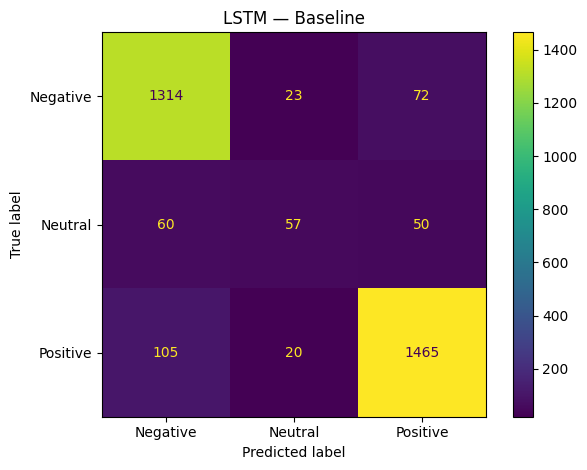

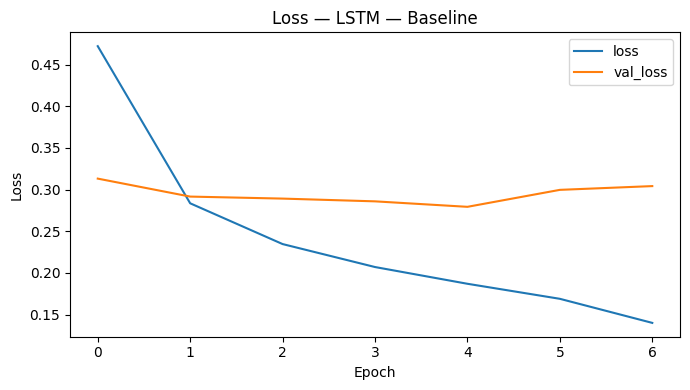

In [ ]:

tf.keras.backend.clear_session()

lstm_baseline = build_lstm_model()
lstm_baseline.summary()

lstm_baseline, history_lstm_baseline = (
    train_and_evaluate_rnn(
        model=lstm_baseline,
        model_name="LSTM",
        experiment="Baseline",
        class_weight=None
    )
)



## 3. LSTM sử dụng trọng số lớp


Epoch 1/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7491 - loss: 0.7228 - val_accuracy: 0.8395 - val_loss: 0.4602 - learning_rate: 0.0010
Epoch 2/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8571 - loss: 0.4656 - val_accuracy: 0.8086 - val_loss: 0.5449 - learning_rate: 0.0010
Epoch 3/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8884 - loss: 0.3456 - val_accuracy: 0.8781 - val_loss: 0.3852 - learning_rate: 5.0000e-04
Epoch 4/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9052 - loss: 0.2975 - val_accuracy: 0.8863 - val_loss: 0.3602 - learning_rate: 5.0000e-04
Epoch 5/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9133 - loss: 0.2577 - val_accuracy: 0.8661 - val_loss: 0.4274 - learning_rate: 5.0000e-04
Epoch 6/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9257 - loss: 0.2171 - val_accuracy: 0.8913 - val_loss: 0.3626 - learning_rate: 2.5000e-04

LSTM — Class Weight
              precision    recall  f1-score   support

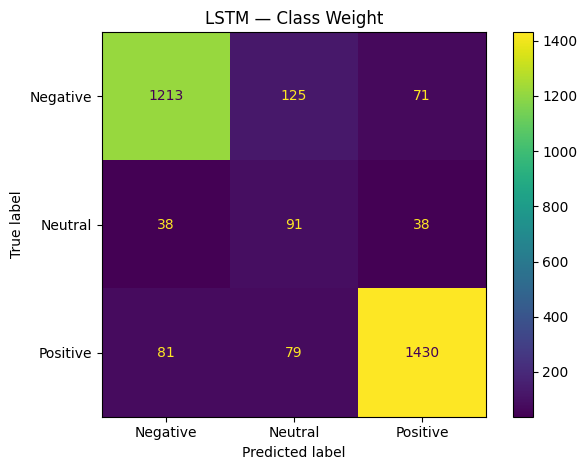

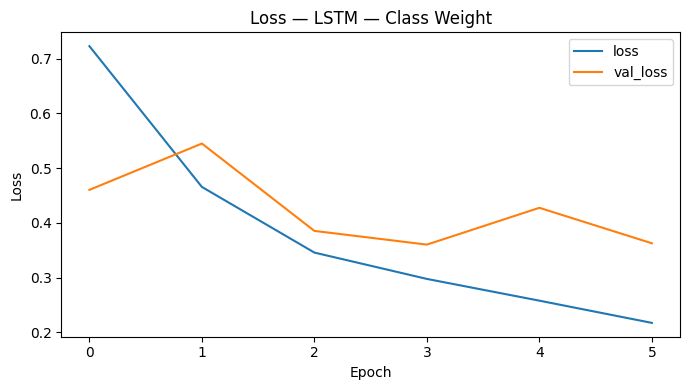

In [ ]:

tf.keras.backend.clear_session()

lstm_balanced = build_lstm_model()

lstm_balanced, history_lstm_balanced = (
    train_and_evaluate_rnn(
        model=lstm_balanced,
        model_name="LSTM",
        experiment="Class Weight",
        class_weight=CLASS_WEIGHT
    )
)


In [ ]:

lstm_results = export_results(
    "lstm_results.csv"
)


,Model,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Negative Precision,Negative Recall,Negative F1,Neutral Precision,Neutral Recall,Neutral F1,Positive Precision,Positive Recall,Positive F1,Neutral Support
0,LSTM,Baseline,0.8958,0.7939,0.7318,0.7531,0.8907,0.8884,0.9326,0.9100,0.5700,0.3413,0.4270,0.9231,0.9214,0.9223,167
1,LSTM,Class Weight,0.8636,0.7161,0.7684,0.7310,0.8737,0.9107,0.8609,0.8851,0.3085,0.5449,0.3939,0.9292,0.8994,0.9140,167


Đã lưu kết quả tại: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/lstm_results.csv


In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import json
import os

SEQUENCE_LENGTH = 80

# Input mới: chuỗi số nguyên thay vì tf.string
token_input = keras.Input(
    shape=(SEQUENCE_LENGTH,),
    dtype=tf.int32,
    name="input_ids"
)

x = token_input

# Lấy lại đúng các layer đã huấn luyện,
# bỏ Input và TextVectorization
start_copy = False

for layer in lstm_balanced.layers:

    if isinstance(
        layer,
        keras.layers.TextVectorization
    ):
        start_copy = True
        continue

    if start_copy:
        x = layer(x)

lstm_numeric = keras.Model(
    inputs=token_input,
    outputs=x,
    name="lstm_numeric"
)

lstm_numeric.summary()

Model: "lstm_numeric"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 80)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 80, 128)   │    322,048 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 80)        │          0 │ input_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 128)       │    131,584 │ embedding[1][0],  │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ lstm[1][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ dropout[1][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[1][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sentiment (Dense)   │ (None, 3)         │        195 │ dropout_1[1][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 462,083 (1.76 MB)

 Trainable params: 462,083 (1.76 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
test_text = "giảng viên nhiệt tình"

# Model gốc
original_probs = (
    lstm_balanced(
        tf.constant([test_text]),
        training=False
    )
    .numpy()[0]
)

# TextVectorization gốc
sequence = text_vectorizer(
    tf.constant([test_text])
)

print(
    "Sequence:",
    sequence.numpy()[0]
)

# Model mới
numeric_probs = (
    lstm_numeric(
        tf.cast(
            sequence,
            tf.int32
        ),
        training=False
    )
    .numpy()[0]
)

print(
    "\nModel gốc:",
    original_probs
)

print(
    "Model numeric:",
    numeric_probs
)

print(
    "\nSai lệch lớn nhất:",
    np.max(
        np.abs(
            original_probs
            - numeric_probs
        )
    )
)

print(
    "\nNhãn model gốc:",
    ID2LABEL[
        int(
            np.argmax(
                original_probs
            )
        )
    ]
)

print(
    "Nhãn model numeric:",
    ID2LABEL[
        int(
            np.argmax(
                numeric_probs
            )
        )
    ]
)

Sequence: [ 5  4 16 11  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0]

Model gốc: [0.01947051 0.01271257 0.9678169 ]
Model numeric: [0.01947051 0.01271257 0.9678169 ]

Sai lệch lớn nhất: 0.0

Nhãn model gốc: Positive
Nhãn model numeric: Positive


In [ ]:
SAVE_DIR = (
    "/content/drive/MyDrive/"
    "NC_MatCanBang_UIT_VSFC/"
    "SavedModels/"
    "lstm_weighted"
)

os.makedirs(
    SAVE_DIR,
    exist_ok=True
)

vocabulary = (
    text_vectorizer
    .get_vocabulary()
)

VOCAB_PATH = os.path.join(
    SAVE_DIR,
    "vocabulary.json"
)

with open(
    VOCAB_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        vocabulary,
        f,
        ensure_ascii=False
    )

print(
    "Đã lưu vocabulary:",
    VOCAB_PATH
)

print(
    "Số từ:",
    len(vocabulary)
)

print(
    "10 token đầu:",
    vocabulary[:10]
)

Đã lưu vocabulary: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/SavedModels/lstm_weighted/vocabulary.json
Số từ: 2516
10 token đầu: ['', '[UNK]', np.str_('.'), np.str_(','), np.str_('viên'), np.str_('giảng'), np.str_('dạy'), np.str_('thầy'), np.str_('sinh'), np.str_('học')]


In [ ]:
!pip install -q tf2onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 72.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 67.4 MB/s eta 0:00:00


In [ ]:
import tf2onnx

ONNX_PATH = os.path.join(
    SAVE_DIR,
    "lstm_model.onnx"
)

input_signature = [
    tf.TensorSpec(
        [None, SEQUENCE_LENGTH],
        tf.int32,
        name="input_ids"
    )
]

model_proto, _ = (
    tf2onnx.convert.from_keras(
        lstm_numeric,
        input_signature=input_signature,
        opset=17,
        output_path=ONNX_PATH
    )
)

print(
    "Đã tạo:",
    ONNX_PATH
)

print(
    "Dung lượng:",
    round(
        os.path.getsize(
            ONNX_PATH
        ) / (1024 ** 2),
        2
    ),
    "MB"
)

ERROR:tf2onnx.tfonnx:Tensorflow op [lstm_numeric_1/lstm_1/CudnnRNNV3: CudnnRNNV3] is not supported
ERROR:tf2onnx.tfonnx:Unsupported ops: Counter({'CudnnRNNV3': 1})


Đã tạo: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/SavedModels/lstm_weighted/lstm_model.onnx
Dung lượng: 1.77 MB


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

SEQUENCE_LENGTH = 80


# =============================
# MODEL DÀNH CHO ONNX
# =============================

token_input = keras.Input(
    shape=(SEQUENCE_LENGTH,),
    dtype=tf.int32,
    name="input_ids"
)

x = layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="embedding"
)(token_input)

# Quan trọng:
# unroll=True => không dùng cuDNN fused op
x = layers.LSTM(
    RNN_UNITS,
    unroll=True,
    name="lstm"
)(x)

x = layers.Dropout(
    0.4,
    name="dropout_1"
)(x)

x = layers.Dense(
    64,
    activation="relu",
    name="dense_hidden"
)(x)

x = layers.Dropout(
    0.3,
    name="dropout_2"
)(x)

output = layers.Dense(
    3,
    activation="softmax",
    name="sentiment"
)(x)

lstm_export = keras.Model(
    inputs=token_input,
    outputs=output,
    name="lstm_export"
)

lstm_export.summary()

Model: "lstm_export"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 80)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 80, 128)   │    322,048 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 80)        │          0 │ input_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 128)       │    131,584 │ embedding[0][0],  │
│                     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_hidden        │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_hidden[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sentiment (Dense)   │ (None, 3)         │        195 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 462,083 (1.76 MB)

 Trainable params: 462,083 (1.76 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Embedding
lstm_export.get_layer(
    "embedding"
).set_weights(
    lstm_balanced
    .get_layer("embedding")
    .get_weights()
)


# LSTM
lstm_export.get_layer(
    "lstm"
).set_weights(
    lstm_balanced
    .get_layer("lstm")
    .get_weights()
)


# Lấy 2 Dense layer của model gốc
original_dense_layers = [
    layer
    for layer in lstm_balanced.layers
    if isinstance(
        layer,
        keras.layers.Dense
    )
]

print(
    "Dense gốc:",
    [layer.name for layer
     in original_dense_layers]
)


# Dense 64
lstm_export.get_layer(
    "dense_hidden"
).set_weights(
    original_dense_layers[0]
    .get_weights()
)


# Dense output 3 lớp
lstm_export.get_layer(
    "sentiment"
).set_weights(
    original_dense_layers[1]
    .get_weights()
)

print(
    "Đã copy toàn bộ trọng số."
)


Dense gốc: ['dense', 'sentiment']
Đã copy toàn bộ trọng số.


In [ ]:
test_text = "giảng viên nhiệt tình"

sequence = text_vectorizer(
    tf.constant([test_text])
)


# Model gốc
original_probs = (
    lstm_balanced(
        tf.constant([test_text]),
        training=False
    )
    .numpy()[0]
)


# Model export
export_probs = (
    lstm_export(
        tf.cast(
            sequence,
            tf.int32
        ),
        training=False
    )
    .numpy()[0]
)


print(
    "Model gốc:",
    original_probs
)

print(
    "Model export:",
    export_probs
)

print(
    "Sai lệch lớn nhất:",
    np.max(
        np.abs(
            original_probs
            - export_probs
        )
    )
)

print(
    "Nhãn model gốc:",
    ID2LABEL[
        int(np.argmax(
            original_probs
        ))
    ]
)

print(
    "Nhãn model export:",
    ID2LABEL[
        int(np.argmax(
            export_probs
        ))
    ]
)

Model gốc: [0.01947051 0.01271257 0.9678169 ]
Model export: [0.01947051 0.01271258 0.9678169 ]
Sai lệch lớn nhất: 4.656613e-09
Nhãn model gốc: Positive
Nhãn model export: Positive


In [ ]:
import os
import tensorflow as tf
import tf2onnx

ONNX_PATH = os.path.join(
    SAVE_DIR,
    "lstm_model.onnx"
)

# Xóa bản ONNX lỗi cũ nếu có
if os.path.exists(ONNX_PATH):
    os.remove(ONNX_PATH)

input_signature = [
    tf.TensorSpec(
        shape=[None, SEQUENCE_LENGTH],
        dtype=tf.int32,
        name="input_ids"
    )
]

model_proto, _ = tf2onnx.convert.from_keras(
    lstm_export,
    input_signature=input_signature,
    opset=17,
    output_path=ONNX_PATH
)

print("Đã tạo:", ONNX_PATH)

print(
    "Dung lượng:",
    round(
        os.path.getsize(ONNX_PATH)
        / (1024 ** 2),
        2
    ),
    "MB"
)

Đã tạo: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/SavedModels/lstm_weighted/lstm_model.onnx
Dung lượng: 2.13 MB


In [ ]:
import onnxruntime as ort
import numpy as np
import tensorflow as tf

session = ort.InferenceSession(
    ONNX_PATH,
    providers=["CPUExecutionProvider"]
)

print("Input ONNX:")
for item in session.get_inputs():
    print(
        item.name,
        item.shape,
        item.type
    )

print("\nOutput ONNX:")
for item in session.get_outputs():
    print(
        item.name,
        item.shape,
        item.type
    )

Input ONNX:
input_ids ['unk__3764', 80] tensor(int32)

Output ONNX:
sentiment ['unk__3765', 3] tensor(float)


In [ ]:
test_text = "giảng viên nhiệt tình"

sequence = text_vectorizer(
    tf.constant([test_text])
).numpy().astype(np.int32)


# TensorFlow export model
tf_probs = lstm_export(
    sequence,
    training=False
).numpy()[0]


# ONNX
input_name = (
    session.get_inputs()[0].name
)

onnx_output = session.run(
    None,
    {
        input_name: sequence
    }
)

onnx_probs = np.asarray(
    onnx_output[0]
)[0]


print(
    "TensorFlow:",
    tf_probs
)

print(
    "ONNX:",
    onnx_probs
)

print(
    "Sai lệch lớn nhất:",
    np.max(
        np.abs(
            tf_probs
            - onnx_probs
        )
    )
)


print(
    "\nNhãn TensorFlow:",
    ID2LABEL[
        int(np.argmax(tf_probs))
    ]
)

print(
    "Nhãn ONNX:",
    ID2LABEL[
        int(np.argmax(onnx_probs))
    ]
)

TensorFlow: [0.01947051 0.01271258 0.9678169 ]
ONNX: [0.01947052 0.01271258 0.9678169 ]
Sai lệch lớn nhất: 1.1175871e-08

Nhãn TensorFlow: Positive
Nhãn ONNX: Positive


In [ ]:
from huggingface_hub import login

login()

In [ ]:
from huggingface_hub import (
    create_repo,
    upload_file
)

LSTM_REPO_ID = (
    "hnhut/"
    "uit-vsfc-lstm-weighted"
)

create_repo(
    repo_id=LSTM_REPO_ID,
    repo_type="model",
    private=False,
    exist_ok=True
)

print(
    "Đã tạo repository:",
    LSTM_REPO_ID
)

Đã tạo repository: hnhut/uit-vsfc-lstm-weighted


In [ ]:
upload_file(
    path_or_fileobj=ONNX_PATH,
    path_in_repo="lstm_model.onnx",
    repo_id=LSTM_REPO_ID,
    repo_type="model",
    commit_message=(
        "Upload LSTM Class Weight ONNX model"
    )
)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ..._weighted/lstm_model.onnx:  28%|##7       |  620kB / 2.23MB            

CommitInfo(commit_url='https://huggingface.co/hnhut/uit-vsfc-lstm-weighted/commit/0c14c28cc47c0140d69a92ec12d8efda148815cb', commit_message='Upload LSTM Class Weight ONNX model', commit_description='', oid='0c14c28cc47c0140d69a92ec12d8efda148815cb', pr_url=None, repo_url=RepoUrl('https://huggingface.co/hnhut/uit-vsfc-lstm-weighted', endpoint='https://huggingface.co', repo_type='model', repo_id='hnhut/uit-vsfc-lstm-weighted'), pr_revision=None, pr_num=None)

In [ ]:
upload_file(
    path_or_fileobj=VOCAB_PATH,
    path_in_repo="vocabulary.json",
    repo_id=LSTM_REPO_ID,
    repo_type="model",
    commit_message=(
        "Upload LSTM vocabulary"
    )
)

print(
    "Đã upload:",
    LSTM_REPO_ID
)

Đã upload: hnhut/uit-vsfc-lstm-weighted
